# Data Prepation 4: Preprocessing

In [21]:
# imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import smogn
import numpy as np
from sklearn.preprocessing import StandardScaler

## 1. Split data into train and test for RF
Columns like 'NORAD_CAT_ID', 'INTLDES', 'SATNAME' can be excluded from the model during the model creation process using ydf

In [22]:
# read data from csv
debris_df = pd.read_csv('../Data/Combined.csv')
debris_df.head()

,NORAD_CAT_ID,INTLDES,SATNAME,OBJECT_TYPE,COUNTRY,SITE,LAUNCH,DECAY,EPOCH,DAYS_SINCE_LAUNCH,...,RA_OF_ASC_NODE,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,REMAINING_LIFETIME,LIFETIME
0,23,1959-009B,JUNO II R/B,ROCKET BODY,US,AFETR,1959-10-13,1989-07-16,1982-01-13,8128,...,233.6360,61.7000,16909.0,0.000982,0.000093,0.0,7012.727,97.406,2741,10869
1,28,1960-002A,THOR ABLE R/B,ROCKET BODY,US,AFETR,1960-04-01,1991-07-03,1987-09-12,10025,...,236.4746,264.6079,46764.0,0.000080,0.000006,0.0,6991.160,96.957,1390,11415
2,30,1960-003A,THOR ABLESTAR R/B,ROCKET BODY,US,AFETR,1960-04-13,1961-08-18,1961-04-17,369,...,272.4964,155.8967,5670.0,0.000000,0.001202,0.0,6750.239,91.989,123,492
3,35,1960-005B,SL-3 R/B,ROCKET BODY,CIS,TTMTR,1960-05-15,1960-07-17,1960-06-08,24,...,183.4791,307.4432,380.0,0.000000,0.001764,0.0,6691.288,90.787,39,63
4,37,1960-005D,SPUTNIK 4 DEB,DEBRIS,CIS,TTMTR,1960-05-15,1961-06-30,1960-05-18,3,...,254.4399,280.1511,63.0,0.000000,0.000000,0.0,6861.776,94.278,408,411


In [23]:
# split the data into training and test sets (80% training, 20% test)
train_df, test_df = train_test_split(debris_df, test_size=0.2, random_state=42)

print("Training set size:", len(train_df))
print("Test set size:", len(test_df))

Training set size: 18417
Test set size: 4605


Training and test set remaining lifetime distribution:


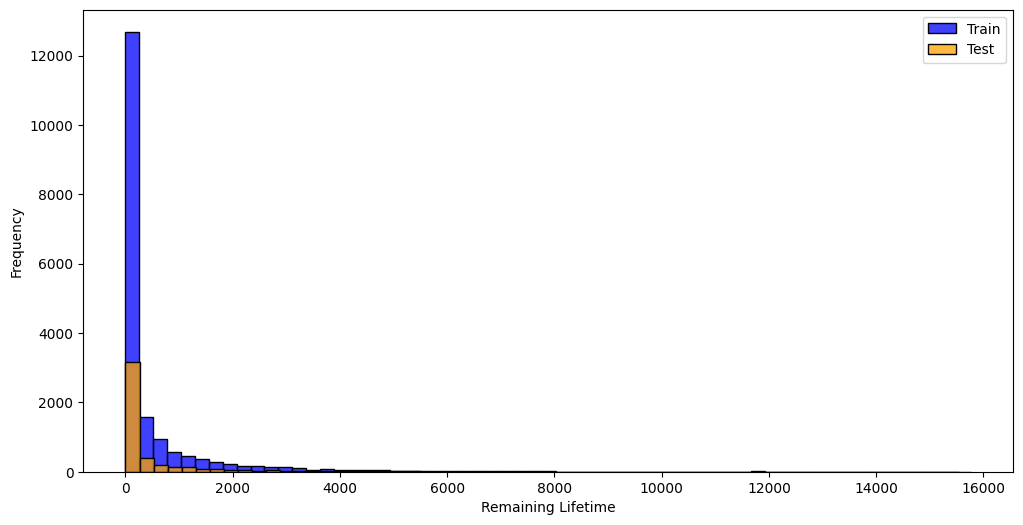

In [24]:
# compare remaining lifetime distribution in training and test sets
print("Training and test set remaining lifetime distribution:")
plt.style.use('default')
plt.figure(figsize=(12, 6))
sns.histplot(train_df['REMAINING_LIFETIME'], bins=60, color='blue', label='Train')
sns.histplot(test_df['REMAINING_LIFETIME'], bins=60, color='orange', label='Test')
plt.xlabel('Remaining Lifetime')
plt.ylabel('Frequency')
plt.legend()
plt.show()

There is a gap in test data around 10000, check if there is a similar gap/few items in train data

In [9]:
# check the number of objects in the train and test set with REMAINING_LIFETIME between 9500 and 10500
print("Number of objects in train with REMAINING_LIFETIME between 9500 and 10500:", len(train_df[(train_df['REMAINING_LIFETIME'] >= 9500) & (train_df['REMAINING_LIFETIME'] <= 10500)]))
print("Number of objects in test with REMAINING_LIFETIME between 9500 and 10500:", len(test_df[(test_df['REMAINING_LIFETIME'] >= 9500) & (test_df['REMAINING_LIFETIME'] <= 10500)]))

Number of objects in train with REMAINING_LIFETIME between 9500 and 10500: 13
Number of objects in test with REMAINING_LIFETIME between 9500 and 10500: 1


In [10]:
# calculate the nearest remaining lifetime below and above 10000 days in the test set
below_10000 = test_df[test_df['REMAINING_LIFETIME'] < 10000]
above_10000 = test_df[test_df['REMAINING_LIFETIME'] > 10000]

# Get the highest remaining lifetime from below_10000
highest_below_10000 = below_10000['REMAINING_LIFETIME'].max()

# Get the lowest remaining lifetime from above_10000
lowest_above_10000 = above_10000['REMAINING_LIFETIME'].min()

print("Highest remaining lifetime below 10000 days in test:", highest_below_10000)
print("Lowest remaining lifetime above 10000 days in test:", lowest_above_10000)

Highest remaining lifetime below 10000 days in test: 9409
Lowest remaining lifetime above 10000 days in test: 10291


In [11]:
# check how many objects have a remaining lifetime above 4000 days
print("Number of objects with remaining lifetime above 4000 days in train:", len(train_df[train_df['REMAINING_LIFETIME'] > 4000]))
print("Number of objects with remaining lifetime above 4000 days in test:", len(test_df[test_df['REMAINING_LIFETIME'] > 4000]))

Number of objects with remaining lifetime above 4000 days in train: 453
Number of objects with remaining lifetime above 4000 days in test: 120


In [12]:
# save to csv
train_df.to_csv("../Data/ModelInput/Train.csv", index=False)
test_df.to_csv("../Data/ModelInput/Test.csv", index=False)
debris_df.to_csv("../Data/DebrisRF.csv", index=False)

## 2. Preprocess data for the MLP

### Handle DateTime colums

In [13]:
# read data from csv
debrisMLP_df = pd.read_csv('../Data/DebrisRF.csv')

# convert LAUNCH and EPOCH columns to datetime format
debrisMLP_df['LAUNCH'] = pd.to_datetime(debrisMLP_df['LAUNCH'])
debrisMLP_df['EPOCH'] = pd.to_datetime(debrisMLP_df['EPOCH'])

# extract year and month from Launch date and insert after Launch column
debrisMLP_df.insert(debrisMLP_df.columns.get_loc('LAUNCH') + 1, 'LAUNCH_YEAR', debrisMLP_df['LAUNCH'].dt.year)
debrisMLP_df.insert(debrisMLP_df.columns.get_loc('LAUNCH') + 2, 'LAUNCH_MONTH', debrisMLP_df['LAUNCH'].dt.month)

# extract year and month from Epoch date and insert after Epoch column
debrisMLP_df.insert(debrisMLP_df.columns.get_loc('EPOCH') + 1, 'EPOCH_YEAR', debrisMLP_df['EPOCH'].dt.year)
debrisMLP_df.insert(debrisMLP_df.columns.get_loc('EPOCH') + 2, 'EPOCH_MONTH', debrisMLP_df['EPOCH'].dt.month)

# drop original Launch and Epoch columns
debrisMLP_df.drop(columns=['LAUNCH', 'EPOCH'], inplace=True)

# save to csv
debrisMLP_df.to_csv("../Data/DebrisMLP.csv", index=False)

### Train/Test split

In [14]:
debrisMLP_df.columns

Index(['NORAD_CAT_ID', 'INTLDES', 'SATNAME', 'OBJECT_TYPE', 'COUNTRY', 'SITE',
       'LAUNCH_YEAR', 'LAUNCH_MONTH', 'DECAY', 'EPOCH_YEAR', 'EPOCH_MONTH',
       'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER',
       'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
       'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT',
       'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD', 'REMAINING_LIFETIME',
       'LIFETIME'],
      dtype='object')

In [15]:
# define feature and label columns
feature_columns = ['NORAD_CAT_ID', 'OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH_YEAR', 'LAUNCH_MONTH', 'EPOCH_YEAR', 'EPOCH_MONTH', 'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
label_column1 = 'LIFETIME'
label_column2 = 'REMAINING_LIFETIME'

x = debrisMLP_df[feature_columns]
y1 = debrisMLP_df[label_column1]
y2 = debrisMLP_df[label_column2]

In [16]:
# split x and y data into train and test
# 80% training, 20% testing
x_train, x_test, y_train_lifetime, y_test_lifetime = train_test_split(x, y1, test_size=0.2, random_state=42)

# use the same indices for the remaining lifetime label
y_train_remaining = y2.loc[y_train_lifetime.index]
y_test_remaining = y2.loc[y_test_lifetime.index]

In [17]:
# show datatypes in x_train
print(x_train.dtypes)

NORAD_CAT_ID           int64
OBJECT_TYPE           object
COUNTRY               object
SITE                  object
LAUNCH_YEAR            int32
LAUNCH_MONTH           int32
EPOCH_YEAR             int32
EPOCH_MONTH            int32
DAYS_SINCE_LAUNCH      int64
PERIAPSIS            float64
APOAPSIS             float64
ARG_OF_PERICENTER    float64
MEAN_MOTION          float64
ECCENTRICITY         float64
INCLINATION          float64
RA_OF_ASC_NODE       float64
MEAN_ANOMALY         float64
REV_AT_EPOCH         float64
BSTAR                float64
MEAN_MOTION_DOT      float64
MEAN_MOTION_DDOT     float64
SEMIMAJOR_AXIS       float64
PERIOD               float64
dtype: object


### One Hot Encoding of categorical features

In [ ]:
# encode non numerical columns using One Hot Encoding 
categorical_cols = x_train.select_dtypes(include=["object"]).columns.tolist()

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False) # unseen cateogorical values in test set will be ignored
x_train_encoded = encoder.fit_transform(x_train[categorical_cols]) # only fit the encoder to training dataset to avoid data leakage
x_test_encoded = encoder.transform(x_test[categorical_cols])

# convert to dataframes
encoded_cols = encoder.get_feature_names_out(categorical_cols)
x_train_encoded = pd.DataFrame(x_train_encoded, columns=encoded_cols, index=x_train.index)
x_test_encoded = pd.DataFrame(x_test_encoded, columns=encoded_cols, index=x_test.index)

# print columns 
print("Encoded categorical columns:")
for col in categorical_cols:
    print(f"- {col}")

Encoded categorical columns:
- OBJECT_TYPE
- COUNTRY
- SITE


### Normalizing numerical features using standardization

In [19]:
# get only numeric columns
numeric_cols = x_train.select_dtypes(include=[np.number]).columns.drop('NORAD_CAT_ID').tolist()

scaler = StandardScaler() # z-score normalization
x_train_scaled = scaler.fit_transform(x_train[numeric_cols]) # only fit scaler on training set to avoid data leakage
x_test_scaled = scaler.transform(x_test[numeric_cols])

# convert to dataframes
x_train_scaled = pd.DataFrame(x_train_scaled, columns=numeric_cols, index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=numeric_cols, index=x_test.index)

# print columns
print("Scaled numeric columns:")
for col in numeric_cols:
    print(f"- {col}")

Scaled numeric columns:
- LAUNCH_YEAR
- LAUNCH_MONTH
- EPOCH_YEAR
- EPOCH_MONTH
- DAYS_SINCE_LAUNCH
- PERIAPSIS
- APOAPSIS
- ARG_OF_PERICENTER
- MEAN_MOTION
- ECCENTRICITY
- INCLINATION
- RA_OF_ASC_NODE
- MEAN_ANOMALY
- REV_AT_EPOCH
- BSTAR
- MEAN_MOTION_DOT
- MEAN_MOTION_DDOT
- SEMIMAJOR_AXIS
- PERIOD


In [20]:
# combinde encoded and normalized features (and ID)
x_train_final = pd.concat([x_train['NORAD_CAT_ID'], x_train_encoded, x_train_scaled], axis=1)
x_test_final = pd.concat([x_test['NORAD_CAT_ID'], x_test_encoded, x_test_scaled], axis=1)

In [21]:
# combine with label columns
x_train_final["LIFETIME"] = y_train_lifetime
x_test_final["LIFETIME"] = y_test_lifetime

x_train_final["REMAINING_LIFETIME"] = y_train_remaining
x_test_final["REMAINING_LIFETIME"] = y_test_remaining

In [22]:
# save to csv
x_train_final.to_csv("../Data/ModelInput/TrainPreprocessed.csv", index=False)
x_test_final.to_csv("../Data/ModelInput/TestPreprocessed.csv", index=False)

## 3. Balancing the dataset
Using Remaining Lifetime as the label and the one hot encoded + normalized features as the input

### Oversampling using SMOTE technique for regression with Gaussian Noise using [smogn](https://pypi.org/project/smogn/) library

In [26]:
# read data from csv
balancing_df = pd.read_csv('../Data/ModelInput/TrainPreprocessed.csv')
balancing_df.drop(columns=['LIFETIME'], inplace=True)

In [4]:
# save IDs from balancing_df
balancing_df['NORAD_CAT_ID'].to_csv("../Data/NoradIDsBeforeBalancing.csv", index=False)
balancing_df.drop(columns=['NORAD_CAT_ID'], inplace=True)

In [7]:
smogn_df = smogn.smoter(
    # main arguments
    data = balancing_df,
    y = 'REMAINING_LIFETIME',        
    k = 5,                    # specifies the number of neighbors to consider for interpolation used in over-sampling (default = 5)
    samp_method = 'extreme',  # string ('balance' or 'extreme', default = 'balance')

    # phi relevance arguments
    rel_thres = 0.8,         # threshold of rarity, positive real number (0 < R < 1), default = 0.50
    rel_method = 'auto',     # string ('auto' or 'manual')
    rel_xtrm_type = 'high',  # string ('low' or 'both' or 'high') -> high to oversample long lifetime objects
    rel_coef = 1.5           # positive real number (0 < R), specifies the box plot coefficient used to automatically determine extreme and therefore rare "minority" values in y, when rel_method = 'auto', default is 1.50
)

r_index: 100%|##########| 2265/2265 [00:02<00:00, 802.19it/s]


In [36]:
print("Before: ", balancing_df.shape[0])
print("After: ", smogn_df.shape[0])
print("Number of lines added:", smogn_df.shape[0] - balancing_df.shape[0])

Before:  18417
After:  27354
Number of lines added: 8937


In [56]:
print("Statistics before smogn:")
print(balancing_df['REMAINING_LIFETIME'].describe())
print("\nStatistics after smogn:")
print(smogn_df['REMAINING_LIFETIME'].describe())

Statistics before smogn:
count    18417.000000
mean       511.440788
std       1179.931550
min          0.000000
25%          6.000000
50%         52.000000
75%        426.000000
max      15553.000000
Name: REMAINING_LIFETIME, dtype: float64

Statistics after smogn:
count    27354.000000
mean      1419.611282
std       1838.632423
min          0.000000
25%         38.000000
50%        930.000000
75%       2007.000000
max      15933.000000
Name: REMAINING_LIFETIME, dtype: float64


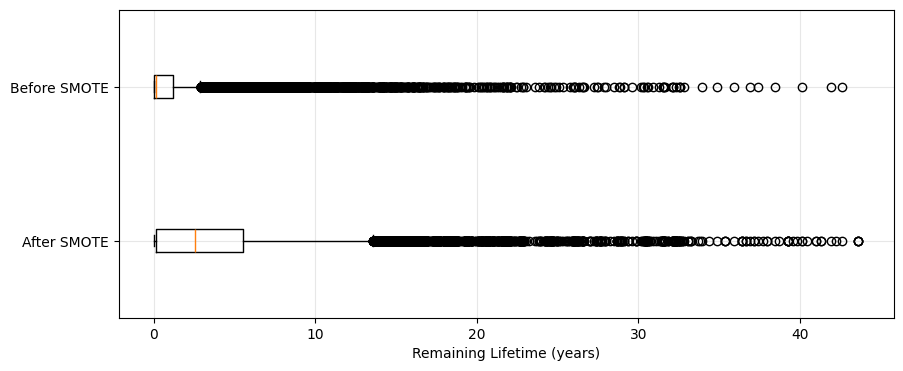

In [53]:
import matplotlib.pyplot as plt

# Define the data
before = balancing_df['REMAINING_LIFETIME'] / 365.25
after = smogn_df['REMAINING_LIFETIME'] / 365.25

# Create the combined boxplot
plt.figure(figsize=(10, 4))
plt.style.use('default')

plt.boxplot([after, before], vert=False, tick_labels=['After SMOTE', 'Before SMOTE'])
plt.xlabel('Remaining Lifetime (years)')
plt.grid(alpha=0.3)
plt.show()

Plot remaining lifetime distribution before and after SMOGN (one bin per year):


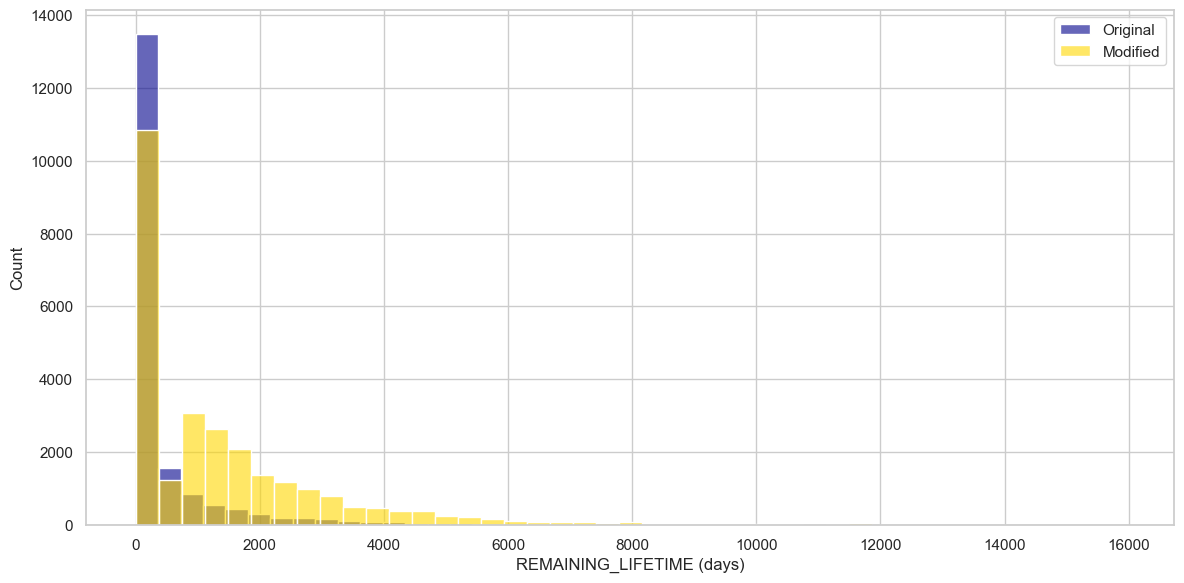

In [30]:
# plot remaining lifetime distribution with one bin per year
sns.set_theme(style="whitegrid")

print("Plot remaining lifetime distribution before and after SMOGN (one bin per year):")
plt.figure(figsize=(12, 6))

# Calculate the number of bins (one bin per year)
max_lifetime = max(balancing_df['REMAINING_LIFETIME'].max(), smogn_df['REMAINING_LIFETIME'].max())
bins = int(max_lifetime / 365)

sns.histplot(balancing_df['REMAINING_LIFETIME'], label="Original", bins=bins, stat="count", color="darkblue", alpha=0.6)
sns.histplot(smogn_df['REMAINING_LIFETIME'], label="Modified", bins=bins, stat="count", color="gold", alpha=0.6)

plt.xlabel("REMAINING_LIFETIME (days)")
plt.ylabel("Count")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Plot remaining lifetime distribution before and after SMOGN with log-scaled y-axis:


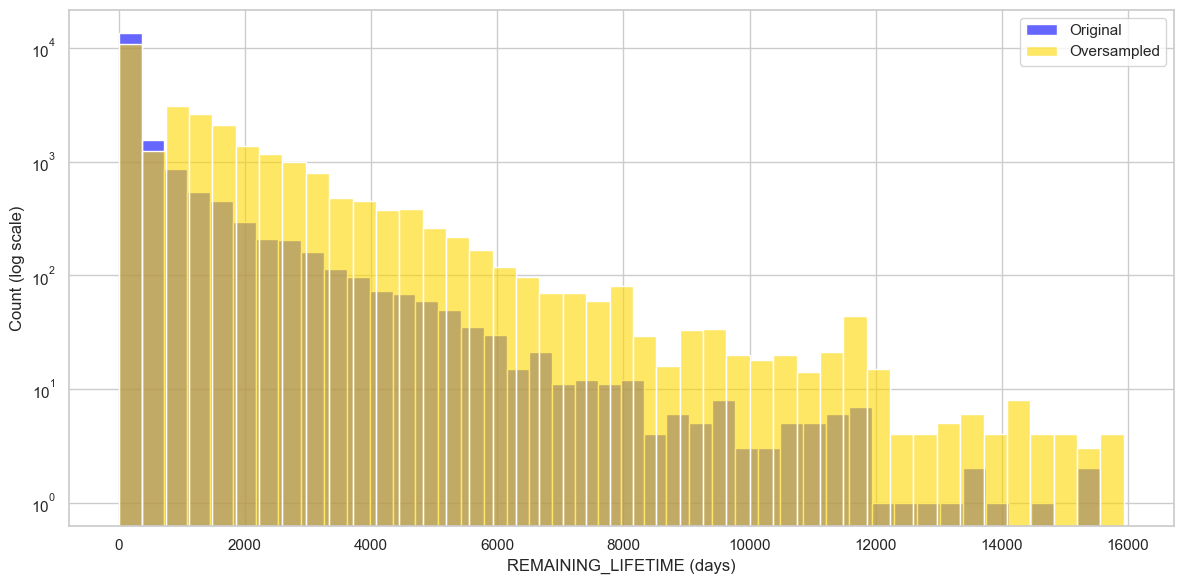

In [34]:
# plot using log scaled y-axis
sns.set_theme(style="whitegrid")
print("Plot remaining lifetime distribution before and after SMOGN with log-scaled y-axis:")
plt.figure(figsize=(12, 6))
sns.histplot(balancing_df['REMAINING_LIFETIME'], label="Original", bins=bins, stat="count", color='blue', alpha=0.6)
sns.histplot(smogn_df['REMAINING_LIFETIME'], label="Oversampled", bins=bins, stat="count", color="gold", alpha=0.6)
plt.yscale('log')
plt.xlabel("REMAINING_LIFETIME (days)")
plt.ylabel("Count (log scale)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
# save to csv
smogn_df.to_csv("../Data/BalancedTrainDataRaw2.csv", index=False)

### Handling One Hot Encoded features with a winner takes it all strategy

In [13]:
# define ohe groups of columns 
one_hot_groups = {
    "OBJECT_TYPE": [col for col in smogn_df.columns if col.startswith("OBJECT_TYPE")],
    "COUNTRY": [col for col in smogn_df.columns if col.startswith("COUNTRY")],
    "SITE": [col for col in smogn_df.columns if col.startswith("SITE")]
}

In [14]:
# function to make the most likely ohe column 1, and the other columns 0
def apply_argmax_to_group(df, columns):
    """
    Applies an argmax operation to the given group of one-hot columns.
    For each row, the index with the highest value is set to 1, 
    and all others are set to 0.
    """
    values = df[columns].values
    max_idx = np.argmax(values, axis=1) # Determine the index of the maximum value for each row
    binary_values = np.zeros_like(values) # Create an array of the same shape filled with zeros
    binary_values[np.arange(len(values)), max_idx] = 1 # Set the maximum value for each row to 1
    df.loc[:, columns] = binary_values # Update the DataFrame columns
    return df

# Apply the function for each defined group
for group, cols in one_hot_groups.items():
    if len(cols) > 0:
        smogn_df = apply_argmax_to_group(smogn_df, cols)

In [15]:
# save to csv
# matching test data is the same as before (TestPreprocessed.csv)
smogn_df.to_csv("../Data/ModelInput/TrainBalancedOHE2.csv", index=False)

In [ ]:
# function to merge OHE columns back to categorical columns for the RF
def merge_ohe_columns_to_categorical(df, one_hot_groups):
    """
    Merges one-hot encoded columns back into their original categorical columns.
    
    Parameters:
    - df (pd.DataFrame): The DataFrame containing the one-hot encoded columns.
    - one_hot_groups (dict): A dictionary where keys are the original categorical column names 
                             and values are lists of one-hot encoded column names.
                             
    Returns:
    - pd.DataFrame: The modified DataFrame with one-hot encoded columns merged back to categorical columns.
    """
    for category_name, columns in one_hot_groups.items():
        # Get the column with the highest value (usually 1)
        df[category_name] = df[columns].idxmax(axis=1)
        # Strip the prefix to get the category value
        df[category_name] = df[category_name].str.replace(f"{category_name}_", "", regex=False)
        # Drop the original one-hot columns
        df = df.drop(columns=columns)
    
    # Reorder columns in the DataFrame
    df = df[[col for col in one_hot_groups.keys()] + [col for col in df.columns if col not in one_hot_groups.keys()]]
    
    return df


In [ ]:
# merge ohe columns in oversampled test data back to categorical columns for the RF
smogn_df = merge_ohe_columns_to_categorical(smogn_df, one_hot_groups)

In [ ]:
# create matching test (using the same columns but not oversampled data) for RF
test_smogn_df = pd.read_csv('../Data/ModelInput/TestPreprocessed.csv')
test_smogn_df = merge_ohe_columns_to_categorical(test_smogn_df, one_hot_groups)

In [19]:
# save to csv
smogn_df.to_csv("../Data/ModelInput/TrainBalanced2.csv", index=False)
test_smogn_df.to_csv("../Data/ModelInput/TestBalanced2.csv", index=False)